# Serie I · Campo — 02. Qué variedades ampliar y cada cuántos cortes renovar

**Pregunta 1 de la prueba:** ¿qué 3 variedades ampliar, cada cuántos cortes renovarlas y qué tan segura es la
recomendación? Con los supuestos económicos de la prueba y considerando que el precio del azúcar es volátil.

**Decisiones tomadas en el notebook 01 (ver `bitacora.md`):**
- Solo etapa 5 para la economía (las etapas tempranas inflan el rendimiento ~1.5×).
- Comparar cada variedad contra testigos del mismo ensayo y corte (el ambiente pesa 4× más que la variedad).
- Mínimo de evidencia: ≥ 2 años en etapa 5, plantía medida y socas medidas al menos hasta soca 2.
- T_SPACRE en libras de azúcar por acre.

**Método, en una línea por paso**
1. Regla fija: 4 variedades testigo que estuvieron en etapa 5 los 12 años.
2. Cada parcela se divide entre el promedio de esos testigos en su mismo ensayo y corte.
3. Por variedad: nivel en plantía y caída por corte, ambos relativos a los testigos (una regresión de 2 parámetros).
4. Curva de rendimiento por variedad → margen por corte → ciclo de renovación con mejor margen anual.
5. Certeza: bootstrap remuestreando ensayos completos, y sensibilidad al precio.
6. Ambientes: ¿la ventaja de cada variedad se mantiene en fincas de bajo potencial?

In [1]:
import sys, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
import statsmodels.api as sm

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from campo_data import load_raw, clean, check_varieties
from campo_economia import (CORE_CHECKS, MAX_CUTS, Supuestos, relative_to_core, clone_parameters, core_curve,
                            clone_curve, cycle_economics, best_cycle, evaluate, break_even_price)

FIG = ROOT / "outputs" / "figures"; TAB = ROOT / "outputs" / "tables"; MOD = ROOT / "outputs" / "models"
for p in (FIG, TAB, MOD): p.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 30)

AZUL, NARANJA, AQUA, GRIS = "#2a78d6", "#eb6834", "#1baf7a", "#9a9993"
TINTA, TINTA2, REJILLA = "#0b0b0b", "#52514e", "#e6e5e1"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": REJILLA, "axes.labelcolor": TINTA2, "xtick.color": TINTA2, "ytick.color": TINTA2,
    "axes.grid": True, "grid.color": REJILLA, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "lines.linewidth": 2,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlecolor": TINTA, "font.size": 10,
})
def guardar(fig, nombre):
    fig.tight_layout(); fig.savefig(FIG / nombre, bbox_inches="tight"); plt.show()

S = Supuestos()   # supuestos de la prueba: US$0.20/lb, US$14/t, US$350/acre/año, US$1,100/acre en plantía
print(S)

Supuestos(precio=0.2, corte=14.0, mantenimiento=350, renovacion=1100, barbecho=0)


In [2]:
df, _ = clean(load_raw(ROOT / "data" / "raw" / "All_Genotypes_2010_onwards.csv"))
TESTIGOS = check_varieties(df)
plot = (df.groupby(["TRIAL","STAGE","LOC","PLANT_YEAR","ENV","CLONE","CROP","YEAR"], as_index=False)
          [["T_SPACRE","TCA","TRS_TON"]].mean())          # promedio de repeticiones = parcela
s5 = plot[plot["STAGE"] == 5].reset_index(drop=True)
print(f"Etapa 5: {len(s5):,} parcelas, {s5['TRIAL'].nunique()} ensayos, {s5['CLONE'].nunique()} variedades, {s5['LOC'].nunique()} localidades")

Etapa 5: 4,708 parcelas, 160 ensayos, 40 variedades, 14 localidades


## 1. Una regla fija para comparar: 4 testigos núcleo

Los testigos cambian con los años (HO12-615 entra en 2016, L03-371 sale en 2017). Si cada variedad se compara
contra "los testigos de su ensayo", las evaluadas en años distintos se miden con reglas distintas. Se usan solo
los testigos presentes en etapa 5 **los 12 años**.

In [3]:
anios_testigo = s5[s5["CLONE"].isin(TESTIGOS)].groupby("CLONE")["YEAR"].nunique().sort_values()
display(anios_testigo.to_frame("años en etapa 5"))
print("Testigos núcleo:", CORE_CHECKS)
cobertura = s5.groupby(["TRIAL","CROP"])["CLONE"].apply(lambda s: s.isin(CORE_CHECKS).sum())
print(f"Grupos ensayo × corte: {len(cobertura)} | con 0 testigos núcleo: {(cobertura == 0).sum()} | "
      f"con 1: {(cobertura == 1).sum()} | con ≥ 2: {(cobertura >= 2).sum()}")

,años en etapa 5
CLONE,
HO13-739,5
HO12-615,6
L12-201,6
L11-183,7
L03-371,8
HOCP09-804,9
L99-226,10
HOCP00-950,10
L01-299,12


Testigos núcleo: ['HOCP04-838', 'HOCP96-540', 'L01-283', 'L01-299']
Grupos ensayo × corte: 459 | con 0 testigos núcleo: 0 | con 1: 8 | con ≥ 2: 451


Todos los grupos ensayo × corte tienen al menos un testigo núcleo (casi todos, dos o más). Para un testigo núcleo,
su referencia excluye su propia parcela (*leave-one-out*), así no se compara contra sí mismo.

## 2. Filtro de evidencia

In [4]:
ev = s5.groupby("CLONE").agg(anios=("YEAR","nunique"), ensayos=("TRIAL","nunique"), parcelas=("CROP","size"),
                             plantia=("CROP", lambda s: (s == 0).any()), ultimo_corte=("CROP","max"))
ev["testigo"] = ev.index.isin(TESTIGOS)
ev["elegible"] = (ev["anios"] >= 2) & ev["plantia"] & (ev["ultimo_corte"] >= 2)
def motivo(r):
    if r.elegible: return "cumple"
    if r.anios < 2: return "un solo año en etapa 5"
    if not r.plantia: return "sin plantía en 2010-2021 (variedad antigua)"
    return "sin soca 2 medida"
ev["motivo"] = ev.apply(motivo, axis=1)
ELEGIBLES = ev.index[ev["elegible"]].tolist()
display(ev.sort_values(["elegible","ensayos"], ascending=False))
print(f"Elegibles: {len(ELEGIBLES)} ({ev.loc[ELEGIBLES,'testigo'].sum()} testigos y {(~ev.loc[ELEGIBLES,'testigo']).sum()} candidatos)")
print(ev["motivo"].value_counts().to_dict())

,anios,ensayos,parcelas,plantia,ultimo_corte,testigo,elegible,motivo
CLONE,,,,,,,,
HOCP96-540,12,152,451,True,4,True,True,cumple
HOCP04-838,12,137,424,True,4,True,True,cumple
L01-299,12,137,393,True,4,True,True,cumple
L01-283,12,116,357,True,4,True,True,cumple
HOCP09-804,9,100,298,True,4,True,True,cumple
HOCP00-950,10,95,277,True,4,True,True,cumple
L99-226,10,95,277,True,4,True,True,cumple
L03-371,8,80,223,True,3,True,True,cumple
HO07-613,10,70,234,True,4,False,True,cumple


Elegibles: 23 (12 testigos y 11 candidatos)
{'cumple': 23, 'un solo año en etapa 5': 13, 'sin plantía en 2010-2021 (variedad antigua)': 3, 'sin soca 2 medida': 1}


## 3. La curva de los testigos núcleo

Es la referencia absoluta: cuánto azúcar da un testigo típico en cada corte. La caída por corte se estima con
efectos fijos de lugar-año (igual que en el notebook 01) para no confundir la edad de la caña con años buenos o malos.

In [5]:
REL = relative_to_core(s5)
CURVA = core_curve(s5)
CURVA["tca"] = CURVA["sugar"] / CURVA["trs"]
display(CURVA.round(3))
eco_ref = cycle_economics(clone_curve(CURVA), S)
display(eco_ref.round(1))
n_ref, v_ref = best_cycle(clone_curve(CURVA), S)
print(f"Testigo núcleo promedio: ciclo óptimo = {n_ref} cortes, margen promedio = US${v_ref:,.0f} por acre al año")

,mult,sugar,trs,tca
corte,,,,
0,1.000,8866.895,275.969,32.130
1,0.946,8385.793,282.741,29.659
2,0.814,7215.399,271.232,26.602
3,0.730,6475.491,261.926,24.723
4,0.611,5414.093,240.609,22.502


,margen_corte,cortes,margen_anual_promedio
corte,,,
0,-126.4,1,-126.4
1,911.9,2,392.7
2,720.6,3,502.0
3,599.0,4,526.3
4,417.8,5,504.6


Testigo núcleo promedio: ciclo óptimo = 4 cortes, margen promedio = US$526 por acre al año


**Lectura de la tabla de márgenes.** La plantía da margen negativo porque carga los US$1,100 de renovación. Las socas
pagan esa inversión. El margen promedio anual sube mientras cada nueva soca deja más que el promedio acumulado, y
baja cuando deja menos. Para el testigo promedio, el óptimo es 4 cortes (plantía + 3 socas).

## 4. Cada variedad contra los testigos: nivel y longevidad

Por variedad se ajusta una recta: `log(rendimiento / testigos) = a + b × corte`.
- `exp(a)` = cuánto rinde en plantía respecto de los testigos (1.10 = 10 % más).
- `exp(b)` = cuánto mejora (>1) o empeora (<1) su ventaja en cada corte adicional: su longevidad relativa.
- TRS relativo = calidad de su caña respecto de los testigos (define cuántas toneladas hay que cortar).

In [6]:
PAR = clone_parameters(REL, ELEGIBLES)
PAR["testigo"] = PAR.index.isin(TESTIGOS)
display(PAR[["plantia_vs_testigos","retencion_vs_testigos","trs_rel","ultimo_corte_medido","anios","ensayos","parcelas","testigo"]]
        .sort_values("plantia_vs_testigos", ascending=False).round(3))

,plantia_vs_testigos,retencion_vs_testigos,trs_rel,ultimo_corte_medido,anios,ensayos,parcelas,testigo
CLONE,,,,,,,,
HOCP14-885,1.181,1.016,1.077,3,4,42,100,False
HO12-615,1.121,0.993,0.994,4,6,64,178,True
HO11-573,1.116,0.921,0.976,4,3,27,43,False
HOL15-508,1.074,1.084,1.100,2,3,31,61,False
HO12-630,1.072,0.938,1.021,2,3,31,59,False
L15-306,1.067,1.074,1.051,2,3,30,60,False
L14-267,1.061,1.047,1.058,3,4,42,100,False
L99-226,1.056,0.977,1.039,4,10,95,277,True
HO07-613,1.056,0.908,1.040,4,10,70,234,False


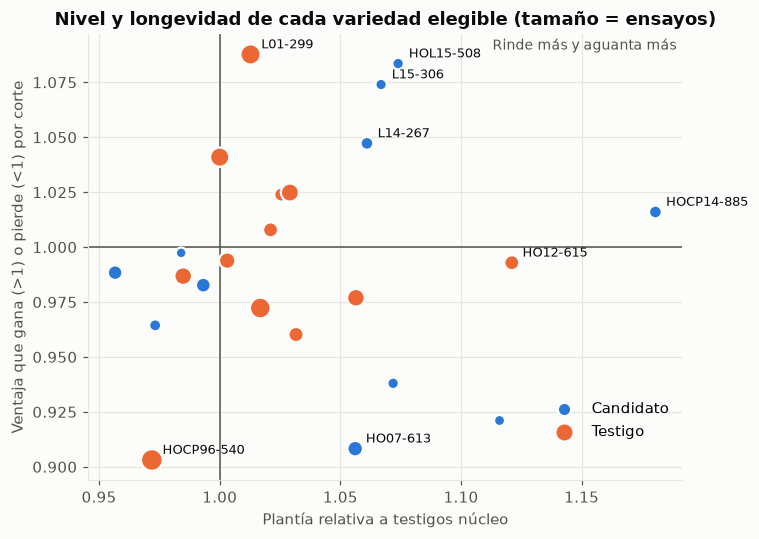

In [7]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.axvline(1, color=TINTA2, linewidth=1); ax.axhline(1, color=TINTA2, linewidth=1)
for t, col, lab in [(False, AZUL, "Candidato"), (True, NARANJA, "Testigo")]:
    d = PAR[PAR["testigo"] == t]
    ax.scatter(d["plantia_vs_testigos"], d["retencion_vs_testigos"], s=20 + d["ensayos"] * 1.2, color=col, label=lab, zorder=3, edgecolor="#fcfcfb", linewidth=1.5)
for c in PAR.index:
    if c in ["HOCP14-885","HOL15-508","L15-306","L14-267","L01-299","HO12-615","HOCP96-540","HO07-613"]:
        ax.annotate(c, (PAR.loc[c,"plantia_vs_testigos"], PAR.loc[c,"retencion_vs_testigos"]), textcoords="offset points", xytext=(7, 4), fontsize=8.5, color=TINTA)
ax.text(0.99, 0.99, "Rinde más y aguanta más", transform=ax.transAxes, ha="right", va="top", color=TINTA2, fontsize=9)
ax.set_xlabel("Plantía relativa a testigos núcleo"); ax.set_ylabel("Ventaja que gana (>1) o pierde (<1) por corte")
ax.set_title("Nivel y longevidad de cada variedad elegible (tamaño = ensayos)")
ax.legend(frameon=False, loc="lower right", bbox_to_anchor=(1, 0.06))
guardar(fig, "serie1_09_nivel_longevidad.png")

**Lectura.** HOCP14-885 es la que más rinde en plantía (+18 %) y conserva esa ventaja. HOL15-508 y L15-306 empiezan
~7 % arriba y su ventaja crece en cada soca, pero eso se midió solo hasta soca 2: hay que cuidar la extrapolación
(sección 5). HOCP96-540 y HO07-613 rinden poco y caen rápido.

## 5. Economía: margen anual y ciclo óptimo por variedad

**Regla conservadora de extrapolación.** HOL15-508 y L15-306 solo tienen datos hasta soca 2. Una recta extrapolada
seguiría aumentando su ventaja en socas 3 y 4. Por defecto, la ventaja relativa **se congela en el último corte
medido**: después de ese corte la variedad cae al ritmo de los testigos. La versión lineal se reporta como sensibilidad.

**Barbecho.** Los supuestos de la prueba no incluyen un año sin caña antes de resembrar; se reporta como sensibilidad
porque en Louisiana es práctica común.

In [8]:
RES = PAR[["plantia_vs_testigos","retencion_vs_testigos","trs_rel","ultimo_corte_medido","anios","ensayos","testigo"]].join(evaluate(PAR, CURVA, S))
lin = evaluate(PAR, CURVA, S, extrapolar=True)
bar = evaluate(PAR, CURVA, Supuestos(barbecho=1))
RES["margen_si_extrapola"] = lin["margen_anual"]; RES["ciclo_si_extrapola"] = lin["ciclo_optimo"]
RES["ciclo_con_barbecho"] = bar["ciclo_optimo"]; RES["margen_con_barbecho"] = bar["margen_anual"]
RES["precio_equilibrio"] = [break_even_price(PAR.loc[c], CURVA, S) for c in RES.index]
RES = RES.sort_values("margen_anual", ascending=False)
RES["rank"] = np.arange(1, len(RES) + 1)
display(RES[["rank","ciclo_optimo","margen_anual","ganancia_vs_testigos","ciclo_extrapolado","ciclo_si_extrapola",
             "margen_si_extrapola","ciclo_con_barbecho","precio_equilibrio","testigo"]].round(3))
print(f"Referencia (testigo núcleo promedio): ciclo {n_ref} cortes, US${v_ref:,.0f}/acre/año")

,rank,ciclo_optimo,margen_anual,ganancia_vs_testigos,ciclo_extrapolado,ciclo_si_extrapola,margen_si_extrapola,ciclo_con_barbecho,precio_equilibrio,testigo
CLONE,,,,,,,,,,
HOCP14-885,1,4,798.103,271.823,False,4,798.103,4,0.113,False
HOL15-508,2,4,776.558,250.277,True,5,807.683,5,0.113,False
L15-306,3,4,733.104,206.824,True,5,756.374,5,0.117,False
L14-267,4,4,701.690,175.410,False,4,701.690,5,0.118,False
L01-299,5,5,701.230,174.949,False,5,701.230,5,0.118,True
HO12-615,6,4,650.414,124.134,False,4,650.414,4,0.123,True
HOCP09-804,7,4,617.676,91.396,False,4,617.676,5,0.123,True
HO13-739,8,4,616.396,90.116,False,4,616.396,5,0.123,True
L01-283,9,4,615.294,89.013,False,4,615.294,5,0.122,True


Referencia (testigo núcleo promedio): ciclo 4 cortes, US$526/acre/año


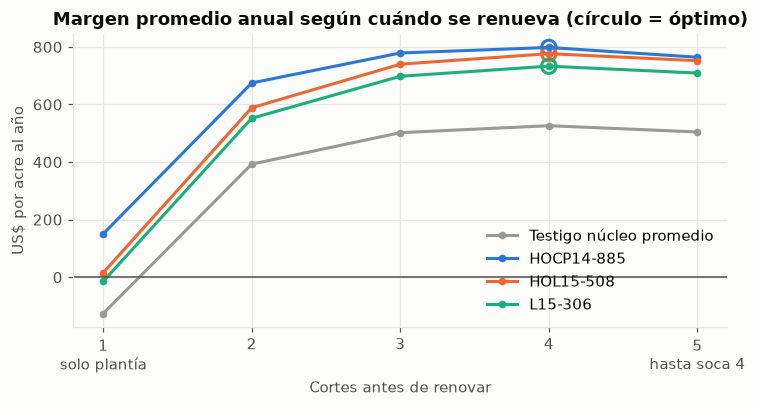

In [9]:
top = RES.index[:6]
fig, ax = plt.subplots(figsize=(7, 3.8))
k = np.arange(1, MAX_CUTS + 1)
ax.plot(k, cycle_economics(clone_curve(CURVA), S)["margen_anual_promedio"], color=GRIS, marker="o", markersize=4, label="Testigo núcleo promedio")
for c, col in zip(RES.index[:3], [AZUL, NARANJA, AQUA]):
    p = PAR.loc[c]
    e = cycle_economics(clone_curve(CURVA, p["a"], p["b"], p["trs_rel"], int(p["ultimo_corte_medido"])), S)
    ax.plot(k, e["margen_anual_promedio"], color=col, marker="o", markersize=4, label=c)
    i = int(e["margen_anual_promedio"].idxmax()); ax.scatter([k[i]], [e["margen_anual_promedio"].iloc[i]], s=90, facecolor="none", edgecolor=col, linewidth=2)
ax.axhline(0, color=TINTA2, linewidth=1)
ax.set_xticks(k); ax.set_xticklabels(["1\nsolo plantía", "2", "3", "4", "5\nhasta soca 4"])
ax.set_xlabel("Cortes antes de renovar"); ax.set_ylabel("US$ por acre al año")
ax.set_title("Margen promedio anual según cuándo se renueva (círculo = óptimo)")
ax.legend(frameon=False, loc="lower right")
guardar(fig, "serie1_10_ciclo_optimo.png")

## 6. ¿Qué tan segura es la recomendación? Bootstrap por ensayos

Se remuestrean **ensayos completos** con reemplazo (no parcelas sueltas, porque las parcelas de un mismo ensayo
comparten lugar, año y suelo). En cada réplica se recalcula todo: comparación contra testigos, curva de los
testigos, parámetros de cada variedad, ciclo óptimo y ranking. 1,000 réplicas, semilla fija.

In [10]:
N_BOOT, SEED = 1000, 20261019
rng = np.random.default_rng(SEED)
ensayos = s5["TRIAL"].unique()
por_ensayo = {t: g for t, g in s5.groupby("TRIAL")}

filas, sin_soca4 = [], 0
for r in range(N_BOOT):
    elegidos = rng.choice(ensayos, len(ensayos), replace=True)
    b = pd.concat([por_ensayo[t].assign(TRIAL=f"{t}#{i}") for i, t in enumerate(elegidos)], ignore_index=True)
    cv = core_curve(b); sin_soca4 += int(np.isnan(cv["mult"].iloc[-1]))
    e = evaluate(clone_parameters(relative_to_core(b), ELEGIBLES), cv, S)
    e["rank"] = e["margen_anual"].rank(ascending=False, method="first")
    filas.append(e.assign(rep=r))
BOOT = pd.concat(filas).reset_index()
BOOT.to_csv(TAB / "serie1_bootstrap.csv", index=False)
print(f"{N_BOOT} réplicas; variedades evaluadas por réplica (mín): {BOOT.groupby('rep').size().min()}")
print(f"Réplicas sin datos de soca 4 de testigos núcleo (ahí el ciclo de 5 cortes no se evalúa): {sin_soca4} ({sin_soca4/N_BOOT:.1%})")

1000 réplicas; variedades evaluadas por réplica (mín): 23
Réplicas sin datos de soca 4 de testigos núcleo (ahí el ciclo de 5 cortes no se evalúa): 48 (4.8%)


In [11]:
def resumen(g):
    modo = g["ciclo_optimo"].mode().iloc[0]
    return pd.Series({
        "P_top3": (g["rank"] <= 3).mean(), "P_top1": (g["rank"] == 1).mean(),
        "P_gana_a_testigos": (g["ganancia_vs_testigos"] > 0).mean(),
        "ganancia_p05": g["ganancia_vs_testigos"].quantile(.05), "ganancia_mediana": g["ganancia_vs_testigos"].median(),
        "ganancia_p95": g["ganancia_vs_testigos"].quantile(.95),
        "ciclo_modal": modo, "P_ciclo_modal": (g["ciclo_optimo"] == modo).mean(),
        "P_ciclo_4o5": g["ciclo_optimo"].isin([4, 5]).mean()})
CERT = BOOT.groupby("CLONE").apply(resumen).reindex(RES.index)
CERT["nivel_certeza_top3"] = pd.cut(CERT["P_top3"], [-0.01, 0.5, 0.8, 1.0], labels=["baja", "media", "alta"])
CERT.to_csv(TAB / "serie1_certeza.csv")
display(CERT.round(3))

,P_top3,P_top1,P_gana_a_testigos,ganancia_p05,ganancia_mediana,ganancia_p95,ciclo_modal,P_ciclo_modal,P_ciclo_4o5,nivel_certeza_top3
CLONE,,,,,,,,,,
HOCP14-885,0.996,0.662,1.000,226.126,271.719,318.800,4.0,0.791,0.934,alta
HOL15-508,0.934,0.331,1.000,183.116,251.212,324.723,4.0,0.824,1.000,alta
L15-306,0.756,0.005,1.000,166.349,208.151,247.645,4.0,0.821,1.000,media
L14-267,0.145,0.001,1.000,138.236,179.021,224.503,4.0,0.790,1.000,baja
L01-299,0.169,0.001,1.000,150.833,175.317,230.818,5.0,0.581,1.000,baja
HO12-615,0.000,0.000,1.000,99.617,124.099,148.886,4.0,0.785,0.918,baja
HOCP09-804,0.000,0.000,1.000,71.887,94.228,118.290,4.0,0.781,1.000,baja
HO13-739,0.000,0.000,1.000,62.180,92.092,125.605,4.0,0.778,1.000,baja
L01-283,0.000,0.000,1.000,73.765,91.894,124.475,4.0,0.715,1.000,baja


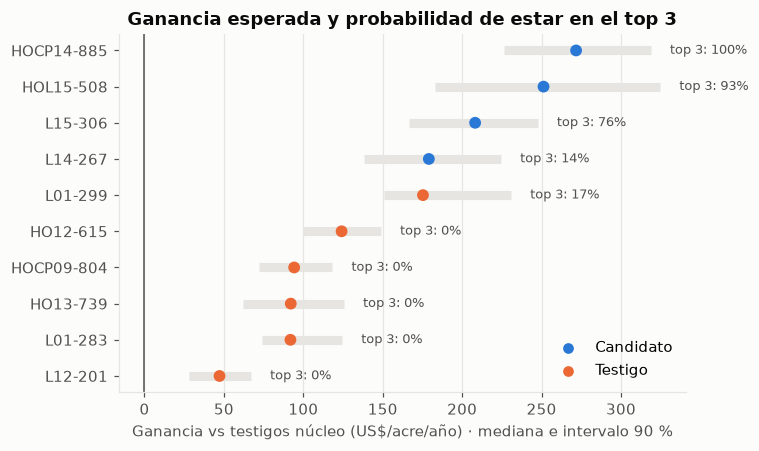

In [12]:
d = CERT.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(7, 4.2))
y = np.arange(len(d))
ax.hlines(y, d["ganancia_p05"], d["ganancia_p95"], color=REJILLA, linewidth=6)
cols = [NARANJA if c in TESTIGOS else AZUL for c in d.index]
ax.scatter(d["ganancia_mediana"], y, color=cols, s=45, zorder=3)
for i, (c, r) in enumerate(d.iterrows()):
    ax.text(r["ganancia_p95"] + 12, i, f"top 3: {r['P_top3']:.0%}", va="center", fontsize=8.5, color=TINTA2)
ax.axvline(0, color=TINTA2, linewidth=1)
ax.set_yticks(y); ax.set_yticklabels(d.index)
ax.set_xlabel("Ganancia vs testigos núcleo (US$/acre/año) · mediana e intervalo 90 %")
ax.set_title("Ganancia esperada y probabilidad de estar en el top 3")
ax.scatter([], [], color=AZUL, label="Candidato"); ax.scatter([], [], color=NARANJA, label="Testigo"); ax.legend(frameon=False, loc="lower right")
ax.grid(axis="y", visible=False)
guardar(fig, "serie1_11_certeza.png")

## 7. El precio es volátil: ¿cambia la recomendación?

Se recalcula todo con precios de US$0.10 a US$0.30 por libra. Se reporta qué variedades quedan en el top 3, cuántos
cortes conviene esperar y el **precio de equilibrio**: el precio mínimo con el que el mejor ciclo de cada variedad
todavía cubre todos sus costos.

In [13]:
precios = np.round(np.arange(0.10, 0.301, 0.02), 2)
sens = []
for p in precios:
    s = Supuestos(precio=float(p))
    e = evaluate(PAR, CURVA, s).sort_values("margen_anual", ascending=False)
    sens.append({"precio": p, "top3": ", ".join(e.index[:3]), "ciclo_referencia": best_cycle(clone_curve(CURVA), s)[0],
                 **{f"ciclo_{c}": int(e.loc[c, "ciclo_optimo"]) for c in RES.index[:3]},
                 **{f"margen_{c}": round(e.loc[c, "margen_anual"]) for c in RES.index[:3]}})
SENS = pd.DataFrame(sens); SENS.to_csv(TAB / "serie1_sensibilidad_precio.csv", index=False)
display(SENS)
display(RES[["precio_equilibrio"]].head(8).round(3).T)

,precio,top3,ciclo_referencia,ciclo_HOCP14-885,ciclo_HOL15-508,ciclo_L15-306,margen_HOCP14-885,margen_HOL15-508,margen_L15-306
0,0.10,"HOL15-508, HOCP14-885, L15-306",5,5,5,5,-117,-115,-142
1,0.12,"HOCP14-885, HOL15-508, L15-306",5,5,5,5,60,58,28
2,0.14,"HOCP14-885, HOL15-508, L15-306",5,4,5,5,238,232,198
3,0.16,"HOCP14-885, HOL15-508, L15-306",4,4,4,4,425,411,374
4,0.18,"HOCP14-885, HOL15-508, L15-306",4,4,4,4,611,594,554
5,0.20,"HOCP14-885, HOL15-508, L15-306",4,4,4,4,798,777,733
6,0.22,"HOCP14-885, HOL15-508, L15-306",4,4,4,4,985,959,913
7,0.24,"HOCP14-885, HOL15-508, L15-306",4,4,4,4,1171,1142,1092
8,0.26,"HOCP14-885, HOL15-508, L15-306",3,3,4,4,1365,1325,1272
9,0.28,"HOCP14-885, HOL15-508, L15-306",3,3,4,4,1561,1507,1451


CLONE,HOCP14-885,HOL15-508,L15-306,L14-267,L01-299,HO12-615,HOCP09-804,HO13-739
precio_equilibrio,0.113,0.113,0.117,0.118,0.118,0.123,0.123,0.123


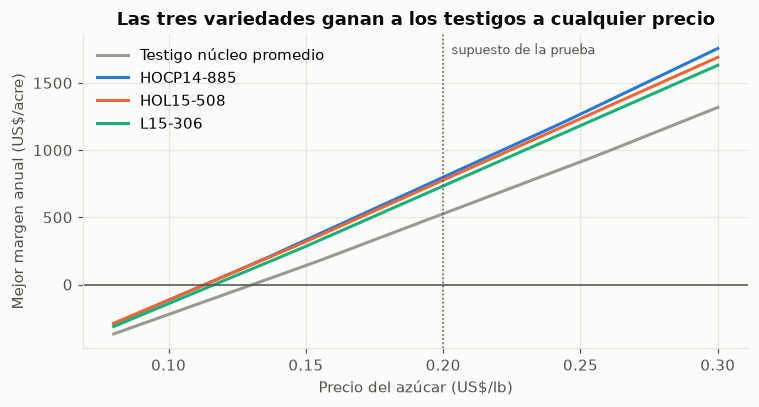

In [14]:
fig, ax = plt.subplots(figsize=(7, 3.8))
grid = np.linspace(0.08, 0.30, 45)
ref = [best_cycle(clone_curve(CURVA), Supuestos(precio=float(p)))[1] for p in grid]
ax.plot(grid, ref, color=GRIS, label="Testigo núcleo promedio")
for c, col in zip(RES.index[:3], [AZUL, NARANJA, AQUA]):
    p_ = PAR.loc[c]; cc = clone_curve(CURVA, p_["a"], p_["b"], p_["trs_rel"], int(p_["ultimo_corte_medido"]))
    ax.plot(grid, [best_cycle(cc, Supuestos(precio=float(p)))[1] for p in grid], color=col, label=c)
ax.axhline(0, color=TINTA2, linewidth=1); ax.axvline(S.precio, color=TINTA2, linewidth=1, linestyle=":")
ax.text(S.precio + 0.003, ax.get_ylim()[1] * 0.92, "supuesto de la prueba", fontsize=8.5, color=TINTA2)
ax.set_xlabel("Precio del azúcar (US$/lb)"); ax.set_ylabel("Mejor margen anual (US$/acre)")
ax.set_title("Las tres variedades ganan a los testigos a cualquier precio")
ax.legend(frameon=False, loc="upper left")
guardar(fig, "serie1_12_precio.png")

## 8. Ambientes: ¿la ventaja se mantiene en fincas pobres?

El dataset no trae coordenadas, altitud ni clima de las localidades (solo un nombre de finca). Además, la zona
cañera de Louisiana es plana y casi al nivel del mar, así que la altitud no distinguiría nada. En lugar de
geolocalizar a mano, el ambiente se caracteriza **con los propios datos**: el rendimiento de los testigos núcleo en
cada localidad-año (índice ambiental). Es la forma estándar en mejoramiento genético y resume clima, suelo y manejo
en una sola medida.

In [15]:
# Índice ambiental "plantía equivalente": rendimiento de testigos núcleo dividido por la caída de su corte
core = REL[REL["CLONE"].isin(CORE_CHECKS)].copy()
core["pce"] = core["T_SPACRE"] / core["CROP"].map(CURVA["mult"])
idx_env = core.groupby("ENV")["pce"].mean().rename("indice")
d = idx_env.reset_index(); d["LOC"] = d["ENV"].str.split("|").str[0]; d["YEAR"] = d["ENV"].str.split("|").str[1]
a = sm.stats.anova_lm(smf.ols("indice ~ C(LOC) + C(YEAR)", data=d).fit(), typ=2)
a["pct"] = 100 * a["sum_sq"] / a["sum_sq"].sum()
display(a[["df","pct"]].round(1))

loc = d.groupby("LOC").agg(potencial=("indice","mean"), anios=("YEAR","nunique"), cv_entre_anios=("indice", lambda s: s.std() / s.mean()))
q = loc["potencial"].quantile([1/3, 2/3]).to_numpy()
loc["grupo"] = np.where(loc["potencial"] <= q[0], "bajo", np.where(loc["potencial"] <= q[1], "medio", "alto"))
loc = loc.sort_values("potencial"); loc.to_csv(TAB / "serie1_localidades.csv")
display(loc.round(3))

,df,pct
C(LOC),13.0,28.7
C(YEAR),11.0,28.0
Residual,117.0,43.3


,potencial,anios,cv_entre_anios,grupo
LOC,,,,
MAGNOLIA,6917.733,12,0.277,bajo
DOMINGUE,7331.446,3,0.235,bajo
MARY,8210.066,12,0.208,bajo
FMARTIN,8294.183,8,0.121,bajo
BRUNSWICK,8394.316,12,0.175,bajo
ALMA,8402.345,12,0.128,medio
HARPER,8605.189,5,0.127,medio
ALLAINS,8669.316,12,0.214,medio
BONSECOUR,9072.791,7,0.066,medio


**Lectura.** La localidad explica ~29 % de la variación del potencial del ambiente y el año otro ~28 %; el resto es la
combinación de ambos. Hay fincas consistentemente mejores (RHEBERT, GLENWOOD) y peores (MAGNOLIA), pero el
ranking de fincas cambia bastante de un año a otro. Clasificar una finca por su potencial es útil, aunque no es una
etiqueta fija.

### Una trampa estadística al medir estabilidad

La primera versión de este análisis comparó la ventaja de cada variedad (variedad ÷ testigos núcleo) contra el índice
ambiental calculado **con esos mismos testigos núcleo**. Salió que casi todas las variedades "rinden relativamente
mejor en ambientes pobres". Es un artefacto: si en un ambiente los testigos tuvieron mala suerte, el índice baja y, a
la vez, la ventaja relativa sube por el mismo ruido (denominador compartido = regresión a la media).

**Corrección:** el índice se calcula con **otras** parcelas del ambiente (todas las que no son testigos núcleo,
excluyendo además a la variedad evaluada). Así el error del índice y el de la ventaja son independientes.

In [16]:
# Multiplicadores de corte comunes (todas las variedades) para llevar cada parcela a "plantía equivalente"
m_all = smf.ols("np.log(T_SPACRE) ~ C(ENV) + C(CLONE) + C(CROP)", data=s5).fit()
mult_all = {0: 1.0, **{k: float(np.exp(m_all.params[f"C(CROP)[T.{k}]"])) for k in range(1, MAX_CUTS)}}
REL["pce"] = REL["T_SPACRE"] / REL["CROP"].map(mult_all)

def pendiente(indice_col, datos):
    out = {}
    for c in ELEGIBLES:
        g = datos[(datos["CLONE"] == c) & datos["rel_sugar"].notna() & datos[indice_col].notna()]
        r = smf.ols(f"np.log(rel_sugar) ~ np.log({indice_col}) + CROP", data=g).fit()
        out[c] = (r.params[f"np.log({indice_col})"], r.pvalues[f"np.log({indice_col})"])
    return pd.DataFrame(out, index=["pendiente", "p"]).T

# (a) versión con trampa: índice de los mismos testigos núcleo
REL["idx_mismo"] = REL["ENV"].map(idx_env)
# (b) versión corregida: índice con parcelas que no son testigos núcleo, sin la variedad evaluada
no_core = REL[~REL["CLONE"].isin(CORE_CHECKS)].groupby("ENV")["pce"].agg(["sum", "count"])
REL = REL.join(no_core, on="ENV")
propio = np.where(REL["CLONE"].isin(CORE_CHECKS), 0.0, REL["pce"]); n_propio = np.where(REL["CLONE"].isin(CORE_CHECKS), 0, 1)
REL["idx_indep"] = (REL["sum"] - propio) / (REL["count"] - n_propio)
REL = REL.drop(columns=["sum", "count"])

comp = pendiente("idx_mismo", REL).add_suffix("_con_trampa").join(pendiente("idx_indep", REL).add_suffix("_corregida"))
print(f"Pendientes negativas: con trampa {(comp['pendiente_con_trampa'] < 0).mean():.0%} | corregida {(comp['pendiente_corregida'] < 0).mean():.0%}")
print(f"Mediana de la pendiente: con trampa {comp['pendiente_con_trampa'].median():.3f} | corregida {comp['pendiente_corregida'].median():.3f}")
display(comp.loc[RES.index].round(3))

Pendientes negativas: con trampa 78% | corregida 61%
Mediana de la pendiente: con trampa -0.065 | corregida -0.020


,pendiente_con_trampa,p_con_trampa,pendiente_corregida,p_corregida
CLONE,,,,
HOCP14-885,0.014,0.795,0.091,0.139
HOL15-508,-0.166,0.011,-0.174,0.021
L15-306,-0.157,0.003,-0.170,0.005
L14-267,-0.136,0.002,-0.107,0.038
L01-299,0.043,0.145,0.079,0.020
HO12-615,-0.090,0.009,-0.082,0.041
HOCP09-804,-0.052,0.152,-0.007,0.871
HO13-739,-0.073,0.064,-0.073,0.114
L01-283,-0.080,0.030,-0.052,0.202


Con el índice independiente, la mediana de la pendiente baja a un tercio (de −0.065 a −0.020) y la proporción de
pendientes negativas cae de 78 % a 61 %: buena parte del patrón "todas rinden relativamente mejor en ambientes pobres"
era el artefacto. Lo que queda son diferencias entre variedades. Algunas cambian de conclusión al corregir
(HO09-840 pasa de −0.14 a 0.01; HOCP96-540 de −0.02 a −0.18), lo que muestra por qué la corrección importa.
**Interpretación de la pendiente:** −0.17 significa que en un ambiente 10 % más rico la ventaja de la variedad sobre
los testigos es ~1.7 % menor. Positiva = la variedad aprovecha mejor los buenos ambientes.

,mean_bajo,mean_medio,mean_alto,size_bajo,size_medio,size_alto,pendiente
CLONE,,,,,,,
HOCP14-885,1.191,1.215,1.226,43,17,40,0.091
HOL15-508,1.172,1.153,1.105,27,11,23,-0.174
L15-306,1.161,1.159,1.075,26,10,24,-0.170
L14-267,1.134,1.135,1.090,42,17,41,-0.107
L01-299,1.124,1.144,1.158,129,130,134,0.079
HO12-615,1.131,1.140,1.098,63,40,75,-0.082


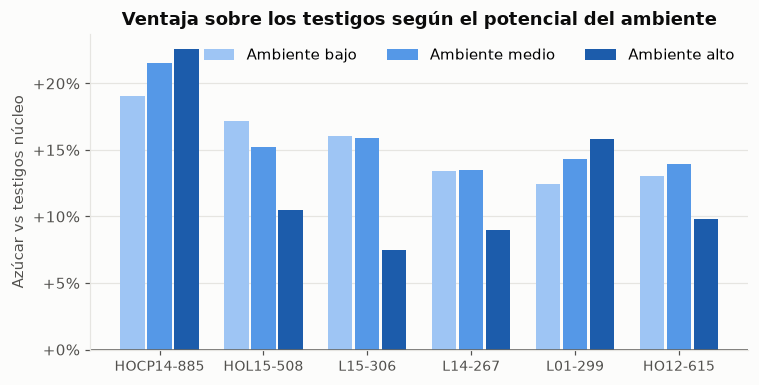

In [17]:
qe = REL["idx_indep"].quantile([1/3, 2/3]).to_numpy()
REL["ambiente"] = pd.cut(REL["idx_indep"], [-np.inf, qe[0], qe[1], np.inf], labels=["bajo", "medio", "alto"])
AMB = (REL[REL["CLONE"].isin(RES.index[:6])].groupby(["CLONE", "ambiente"], observed=True)["rel_sugar"]
         .agg(["mean", "size"]).unstack())
AMB.columns = [f"{a}_{b}" for a, b in AMB.columns]
AMB = AMB.loc[RES.index[:6]]; AMB["pendiente"] = comp.loc[AMB.index, "pendiente_corregida"]
AMB.to_csv(TAB / "serie1_ambientes_top.csv"); display(AMB.round(3))

fig, ax = plt.subplots(figsize=(7, 3.6))
grupos = ["bajo", "medio", "alto"]; w = 0.26; x = np.arange(len(AMB))
for j, (g, col) in enumerate(zip(grupos, ["#9ec5f4", "#5598e7", "#1c5cab"])):   # rampa ordinal de un solo tono
    ax.bar(x + (j - 1) * w, AMB[f"mean_{g}"] - 1, width=w * 0.9, color=col, label=f"Ambiente {g}")
ax.axhline(0, color=TINTA2, linewidth=1)
ax.set_xticks(x); ax.set_xticklabels(AMB.index, fontsize=9)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:+.0%}"))
ax.set_ylabel("Azúcar vs testigos núcleo"); ax.set_title("Ventaja sobre los testigos según el potencial del ambiente")
ax.legend(frameon=False, ncol=3, loc="upper right"); ax.grid(axis="x", visible=False)
guardar(fig, "serie1_13_ambientes.png")

## 9. Artefacto para la API y tablas finales

In [18]:
artefacto = {
    "descripcion": "Serie I · curvas de rendimiento relativas a testigos núcleo, etapa 5 Louisiana 2010-2021",
    "supuestos": S.__dict__, "testigos_nucleo": CORE_CHECKS, "max_cortes": MAX_CUTS,
    "curva_testigos": CURVA.reset_index().to_dict(orient="records"),
    "variedades": {c: {**{k: (float(v) if isinstance(v, (int, float, np.floating, np.integer)) else bool(v)) for k, v in
                          PAR.loc[c, ["a","b","trs_rel","plantia_vs_testigos","retencion_vs_testigos","ultimo_corte_medido","anios","ensayos","parcelas","testigo"]].items()},
                       "P_top3": float(CERT.loc[c, "P_top3"]), "ganancia_p05": float(CERT.loc[c, "ganancia_p05"]),
                       "ganancia_p95": float(CERT.loc[c, "ganancia_p95"])} for c in PAR.index},
}
(MOD / "serie1_curvas.json").write_text(json.dumps(artefacto, ensure_ascii=False, indent=1), encoding="utf-8")
RES.join(CERT).to_csv(TAB / "serie1_recomendacion.csv")
print("Guardado:", (MOD / "serie1_curvas.json").relative_to(ROOT).as_posix())

# Resumen de cifras para el documento explicativo (docs/)
_idx = idx_env.reset_index(); _idx["LOC"] = _idx["ENV"].str.split("|").str[0]; _idx["YEAR"] = _idx["ENV"].str.split("|").str[1]
_an = sm.stats.anova_lm(smf.ols("indice ~ C(LOC) + C(YEAR)", data=_idx).fit(), typ=2)
resumen_q1 = {
    "n_variedades_etapa5": int(len(ev)), "n_elegibles": len(ELEGIBLES),
    "n_elegibles_testigos": int(ev.loc[ELEGIBLES, "testigo"].sum()), "motivos": ev["motivo"].value_counts().to_dict(),
    "bootstrap": {"replicas": N_BOOT, "semilla": SEED, "sin_soca4": int(sin_soca4)},
    "referencia": {"ciclo": int(n_ref), "margen": float(v_ref)},
    "ambiente_pct": {k: float(v) for k, v in (100 * _an["sum_sq"] / _an["sum_sq"].sum()).items()},
    "trampa": {"neg_con_trampa": float((comp["pendiente_con_trampa"] < 0).mean()), "neg_corregida": float((comp["pendiente_corregida"] < 0).mean()),
               "mediana_con_trampa": float(comp["pendiente_con_trampa"].median()), "mediana_corregida": float(comp["pendiente_corregida"].median())},
}
(TAB / "serie1_resumen_q1.json").write_text(json.dumps(resumen_q1, ensure_ascii=False, indent=1), encoding="utf-8")
print(resumen_q1)

Guardado: outputs/models/serie1_curvas.json
{'n_variedades_etapa5': 40, 'n_elegibles': 23, 'n_elegibles_testigos': 12, 'motivos': {'cumple': 23, 'un solo año en etapa 5': 13, 'sin plantía en 2010-2021 (variedad antigua)': 3, 'sin soca 2 medida': 1}, 'bootstrap': {'replicas': 1000, 'semilla': 20261019, 'sin_soca4': 48}, 'referencia': {'ciclo': 4, 'margen': 526.2805475965661}, 'ambiente_pct': {'C(LOC)': 28.689548079795742, 'C(YEAR)': 28.049049231701236, 'Residual': 43.26140268850302}, 'trampa': {'neg_con_trampa': 0.782608695652174, 'neg_corregida': 0.6086956521739131, 'mediana_con_trampa': -0.06483791052439654, 'mediana_corregida': -0.019920359126424737}}


In [19]:
# Verificación: el JSON reproduce el ciclo y el margen de cada variedad (lo que usará la API)
art = json.loads((MOD / "serie1_curvas.json").read_text(encoding="utf-8"))
curva_j = pd.DataFrame(art["curva_testigos"]).set_index("corte")
par_j = pd.DataFrame(art["variedades"]).T[["a", "b", "trs_rel", "ultimo_corte_medido"]].astype(float)
ev_j = evaluate(par_j, curva_j, Supuestos(**art["supuestos"]))
dif = (ev_j.loc[RES.index, "margen_anual"] - RES["margen_anual"]).abs().max()
mismos = bool((ev_j.loc[RES.index, "ciclo_optimo"] == RES["ciclo_optimo"]).all())
print(f"Verificación del JSON: {len(ev_j)} variedades | diferencia máxima de margen {dif:.1e} US$/acre | "
      f"ciclos iguales: {mismos} | referencia US${ev_j.attrs['referencia']['margen_anual']:.1f}/acre/año")
assert dif < 1e-6 and mismos

Verificación del JSON: 23 variedades | diferencia máxima de margen 0.0e+00 US$/acre | ciclos iguales: True | referencia US$526.3/acre/año


## 10. Evaluación gerencial

In [20]:
top3 = RES.index[:3]
ha = 2.471  # acres por hectárea
for c in top3:
    r, k = RES.loc[c], CERT.loc[c]
    print(f"{c}: renovar cada {int(r['ciclo_optimo'])} cortes | +US${r['ganancia_vs_testigos']:,.0f}/acre/año "
          f"(IC90 {k['ganancia_p05']:,.0f} a {k['ganancia_p95']:,.0f}) ≈ +US${r['ganancia_vs_testigos']*ha:,.0f}/ha/año | "
          f"P(top 3) {k['P_top3']:.0%} | P(gana a testigos) {k['P_gana_a_testigos']:.0%} | equilibrio US${r['precio_equilibrio']:.3f}/lb")
print(f"\nReferencia: testigo núcleo promedio, ciclo {n_ref} cortes, US${v_ref:,.0f}/acre/año")
print(f"Impacto ilustrativo por 1,000 acres (405 ha) con la variedad #1 en lugar del testigo promedio: "
      f"US${RES.iloc[0]['ganancia_vs_testigos']*1000:,.0f}/año (IC90 {CERT.iloc[0]['ganancia_p05']*1000:,.0f} a {CERT.iloc[0]['ganancia_p95']*1000:,.0f})")

HOCP14-885: renovar cada 4 cortes | +US$272/acre/año (IC90 226 a 319) ≈ +US$672/ha/año | P(top 3) 100% | P(gana a testigos) 100% | equilibrio US$0.113/lb
HOL15-508: renovar cada 4 cortes | +US$250/acre/año (IC90 183 a 325) ≈ +US$618/ha/año | P(top 3) 93% | P(gana a testigos) 100% | equilibrio US$0.113/lb
L15-306: renovar cada 4 cortes | +US$207/acre/año (IC90 166 a 248) ≈ +US$511/ha/año | P(top 3) 76% | P(gana a testigos) 100% | equilibrio US$0.117/lb

Referencia: testigo núcleo promedio, ciclo 4 cortes, US$526/acre/año
Impacto ilustrativo por 1,000 acres (405 ha) con la variedad #1 en lugar del testigo promedio: US$271,823/año (IC90 226,126 a 318,800)


**Qué significa para el ingenio.** En estos datos hay variedades que, comparadas en el mismo campo y año, dejan entre
US$200 y US$270 más por acre al año que el testigo promedio. La diferencia viene sobre todo del rendimiento de azúcar,
y en las tres mejores también de que su ventaja no se pierde en las socas.

**Decisión recomendada.**
1. Ampliar **HOCP14-885** (la de mayor evidencia: 4 años, hasta soca 3) y, en escala de validación, **HOL15-508** y
   **L15-306** (medidas solo hasta soca 2).
2. Renovar cada **4 cortes** (plantía + 3 socas). El óptimo es plano entre 4 y 5 cortes: si un lote llega a la 4.ª soca
   con buen rendimiento, mantenerlo no destruye valor.
3. No usar la ventaja de HOL15-508 y L15-306 más allá de la soca 2 sin datos: medirlas hasta soca 4 antes de escalar.

**Impacto estimado.** Ver la celda anterior: ganancia por acre y su intervalo, y el impacto ilustrativo por 1,000 acres.

**Riesgos.**
- *Validez externa:* son datos de Louisiana (clima subtropical, heladas, ciclos cortos). Las variedades no se
  trasladan a Guatemala; lo que se traslada es el método. Para el ingenio, esta recomendación es un protocolo, no una lista
  de compra.
- *Extrapolación:* HOL15-508 y L15-306 no tienen soca 3 medida.
- *Precio:* bajo ~US$0.11-0.12/lb ninguna variedad cubre costos (precio de equilibrio). Las mismas tres variedades
  encabezan en todo el rango US$0.10-0.30: el precio cambia **cuánto** se gana, no **cuál** variedad elegir. Sí cambia
  **cuándo** renovar: con precios altos (≥ US$0.26) conviene renovar antes (3-4 cortes) porque la caña joven vale más;
  con precios bajos (≤ US$0.14) conviene estirar a 5 cortes.
- *Barbecho:* si se cuenta un año sin caña antes de resembrar, el ciclo óptimo sube a 5 cortes para varias variedades.

**Nivel de certeza.** Alta para HOCP14-885 y HOL15-508 (en el top 3 en ≥ 93 % de las réplicas), media para
L15-306 (76 %). L14-267 y L01-299 tienen intervalos que se traslapan con L15-306: son la alternativa natural si L15-306 no
confirma su desempeño en socas 3-4. Las tres le ganan al testigo promedio en el 100 % de las réplicas.
La incertidumbre del bootstrap es solo estadística; no cubre el riesgo de trasladar resultados de Louisiana a Guatemala.